# Exploratory Data Analysis
## Reddit r/politics — 2024 US Presidential Election

**Pipeline:** Data_preparation.ipynb → VADER_Labeling.ipynb → **EDA.ipynb** → NLP_Final_Project.ipynb

Comprehensive EDA of **6.6M Reddit comments** covering:
data quality, temporal patterns, text characteristics, candidate framing,
engagement, VADER sentiment analysis, and correlation with real-world polling data.

> The unit of analysis is the **comment**. Posts are background context only.

## 0. Imports & Setup

pip install vaderSentiment wordcloud

In [1]:
import warnings
warnings.filterwarnings('ignore')

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from collections import Counter
from scipy import stats

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
from nltk.corpus import stopwords
from nltk.util import ngrams

BASE_DIR = Path('..').resolve()
DATA_DIR = BASE_DIR / 'Datasources'

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'sans-serif'
sns.set_style('whitegrid')

EVENTS = {
    '2024-06-27': 'Biden-Trump debate',
    '2024-07-13': 'Trump assassination attempt',
    '2024-07-21': 'Biden drops out',
    '2024-08-06': 'Walz VP pick',
    '2024-09-10': 'Harris-Trump debate',
    '2024-10-01': 'Walz-Vance VP debate',
    '2024-10-05': '2nd assassination attempt',
    '2024-11-05': 'Election Day',
}

MONTH_ORDER = ['June', 'July', 'August', 'September', 'October', 'November']
CANDIDATE_COLORS = {'Trump': '#d62728', 'Harris': '#1f77b4'}


## 1. Load Data

In [2]:
df_comments = pd.read_parquet(DATA_DIR / 'df_comments_vader.parquet')
df_comments['date']     = pd.to_datetime(df_comments['date'])
df_comments['date_day'] = pd.to_datetime(df_comments['date_day'])

months_present = [m for m in MONTH_ORDER if m in df_comments['month'].values]

print(f'Comments: {len(df_comments):,} | {df_comments["date"].min().date()} -> {df_comments["date"].max().date()}')
print(f'Columns:  {df_comments.columns.tolist()}')

Comments: 6,553,662 | 2024-06-01 -> 2024-11-06
Columns:  ['comment_id', 'post_id', 'parent_id', 'is_top_level', 'body', 'score', 'date', 'month', 'date_day', 'post_title', 'vader_score', 'vader_label']


## 2. Data Quality

Check for missing values, duplicates, **bot comments**, deleted/removed content, very short comments, and date gaps.

Bot comments are identified via substring matching on known AutoModerator / bot phrases and removed before all downstream analysis.

In [3]:
print('=== Missing Values (comments) ===')
print(df_comments.isnull().sum()[df_comments.isnull().sum() > 0])

print('\n=== Duplicates ===')
print(f'Duplicate comment ids: {df_comments["comment_id"].duplicated().sum():,}')

=== Missing Values (comments) ===
Series([], dtype: int64)

=== Duplicates ===
Duplicate comment ids: 0


In [4]:
BOT_PATTERNS = [
    'i am a bot','i\'m a bot', 'automoderator', 'this is a bot',
    'message the moderators', 'moderators message compose',
    'action was performed automatically', 'please contact the moderators',
    'approved domains list', 'politics wiki', 'bot action performed',
    'performed automatically', 'compose politics',
]

def is_bot(text: str) -> bool:
    t = str(text).lower()
    return any(p in t for p in BOT_PATTERNS)

bot_mask = df_comments['body'].apply(is_bot)
n_before = len(df_comments)
n_bots   = bot_mask.sum()

print(f'Total comments (before): {n_before:,}')
print(f'Bot comments detected:   {n_bots:,} ({n_bots/n_before*100:.2f}%)')
print()
print('Sample bot messages (first 3):')
for body in df_comments[bot_mask]['body'].head(3):
    print(f'  > {str(body)[:120]}\n')

# ── Filter in place ───────────────────────────────────────────────────────
df_comments = df_comments[~bot_mask].reset_index(drop=True)
months_present = [m for m in MONTH_ORDER if m in df_comments['month'].values]

print(f'Clean comments (after):  {len(df_comments):,}')

Total comments (before): 6,553,662
Bot comments detected:   0 (0.00%)

Sample bot messages (first 3):
Clean comments (after):  6,553,662


In [5]:
#save modified dataset without bot comments
out_path = DATA_DIR / 'df_comments_vader.parquet'
df_comments.to_parquet(out_path, index=False)

print(f'Saved {len(df_comments):,} labeled comments to:')
print(f'  {out_path}')

Saved 6,553,662 labeled comments to:
  D:\Github\NLP_reddit\Datasources\df_comments_vader.parquet


In [6]:
# Deleted / removed / very short content
deleted_mask = df_comments['body'].str.strip().isin(['[deleted]', '[removed]', ''])
very_short   = df_comments['body'].str.len() < 10

print(f'[deleted]/[removed]/empty: {deleted_mask.sum():,} ({deleted_mask.mean()*100:.2f}%)')
print(f'Very short (<10 chars):    {very_short.sum():,} ({very_short.mean()*100:.2f}%)')
print(f'Usable comments:           {(~deleted_mask).sum():,}')

special = df_comments['body'].str.strip().value_counts().head(10)
print('\nMost common body values (top 10):')
print(special)


[deleted]/[removed]/empty: 0 (0.00%)
Very short (<10 chars):    129,407 (1.97%)
Usable comments:           6,553,662

Most common body values (top 10):
body
Yes        2650
No         1602
Yes.       1433
Source?    1175
No.        1050
Good        988
Why?        980
Good.       872
What?       853
Exactly     842
Name: count, dtype: int64


In [7]:
# Check for missing days in the timeline
full_range = pd.date_range(
    start=df_comments['date_day'].min(),
    end=df_comments['date_day'].max(),
    freq='D'
)
days_present = set(df_comments['date_day'].dt.normalize().unique())
missing_days = [d for d in full_range if d not in days_present]

print(f'Expected days in range:          {len(full_range)}')
print(f'Days with at least 1 comment:    {len(days_present)}')
print(f'Days with 0 comments (gaps):     {len(missing_days)}')
if missing_days:
    print('\nMissing dates:')
    for d in missing_days:
        print(f'  {d.date()}')
else:
    print('\nNo gaps — all days covered.')

# Flag days with suspiciously low comment counts (bottom 5%)
daily_counts = df_comments.groupby('date_day').size()
threshold = daily_counts.quantile(0.05)
low_days = daily_counts[daily_counts < threshold].sort_values()
print(f'\nDays with suspiciously low count (bottom 5%, <{threshold:.0f} comments):')
for date, count in low_days.items():
    print(f'  {date.date()}: {count:,} comments')


Expected days in range:          159
Days with at least 1 comment:    158
Days with 0 comments (gaps):     1

Missing dates:
  2024-08-30

Days with suspiciously low count (bottom 5%, <12738 comments):
  2024-07-31: 865 comments
  2024-06-22: 7,155 comments
  2024-06-08: 10,393 comments
  2024-06-23: 11,212 comments
  2024-06-09: 11,793 comments
  2024-06-17: 12,172 comments
  2024-06-15: 12,565 comments
  2024-06-18: 12,727 comments


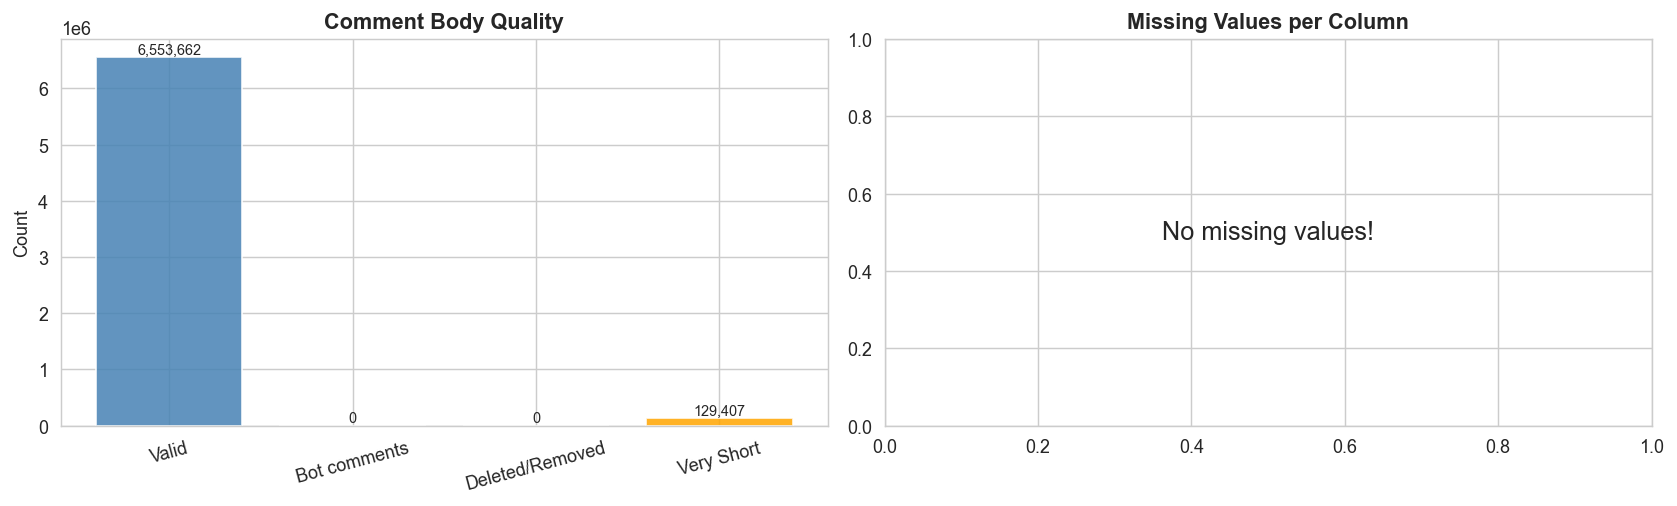

Bot comments removed before this point: 0 (0.00% of raw total)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# --- Left: comment body quality breakdown ---
bar_labels  = ['Valid', 'Bot comments', 'Deleted/Removed', 'Very Short']
bar_values  = [(~deleted_mask).sum(), n_bots, deleted_mask.sum(), very_short.sum()]
bar_colors  = ['steelblue', '#9467bd', '#d62728', 'orange']
axes[0].bar(bar_labels, bar_values, color=bar_colors, alpha=0.85)
axes[0].set_title('Comment Body Quality', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(bar_values):
    axes[0].text(i, v + max(bar_values) * 0.01, f'{v:,}', ha='center', fontsize=8)

# --- Right: missing values per column ---
missing = df_comments.isnull().mean() * 100
missing = missing[missing > 0]
if len(missing) > 0:
    axes[1].barh(missing.index, missing.values, color='#d62728', alpha=0.8)
    axes[1].set_title('% Missing Values per Column', fontweight='bold')
    axes[1].set_xlabel('% missing')
else:
    axes[1].text(0.5, 0.5, 'No missing values!', ha='center', va='center',
                 fontsize=14, transform=axes[1].transAxes)
    axes[1].set_title('Missing Values per Column', fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Bot comments removed before this point: {n_bots:,} ({n_bots/(n_before)*100:.2f}% of raw total)')

## 3. Volume & Temporal Patterns

Monthly and daily comment volume, day-of-week activity, and hour-of-day rhythms.

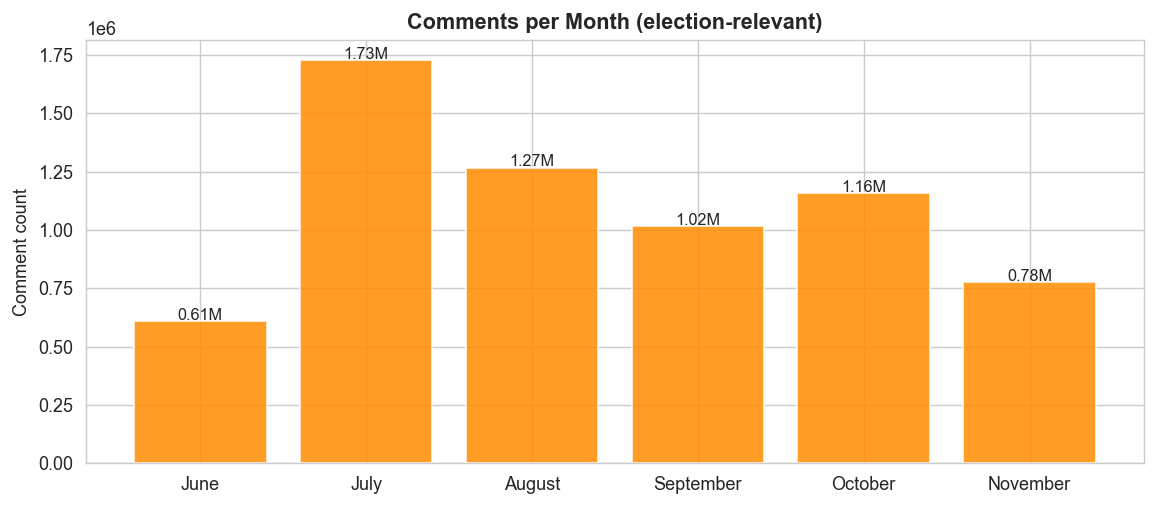

In [9]:
comment_counts = df_comments['month'].value_counts().reindex(months_present)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comment_counts.index, comment_counts.values, color='darkorange', alpha=0.85)
ax.set_title('Comments per Month (election-relevant)', fontweight='bold')
ax.set_ylabel('Comment count')
for i, v in enumerate(comment_counts.values):
    ax.text(i, v + 5000, f'{v/1e6:.2f}M', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

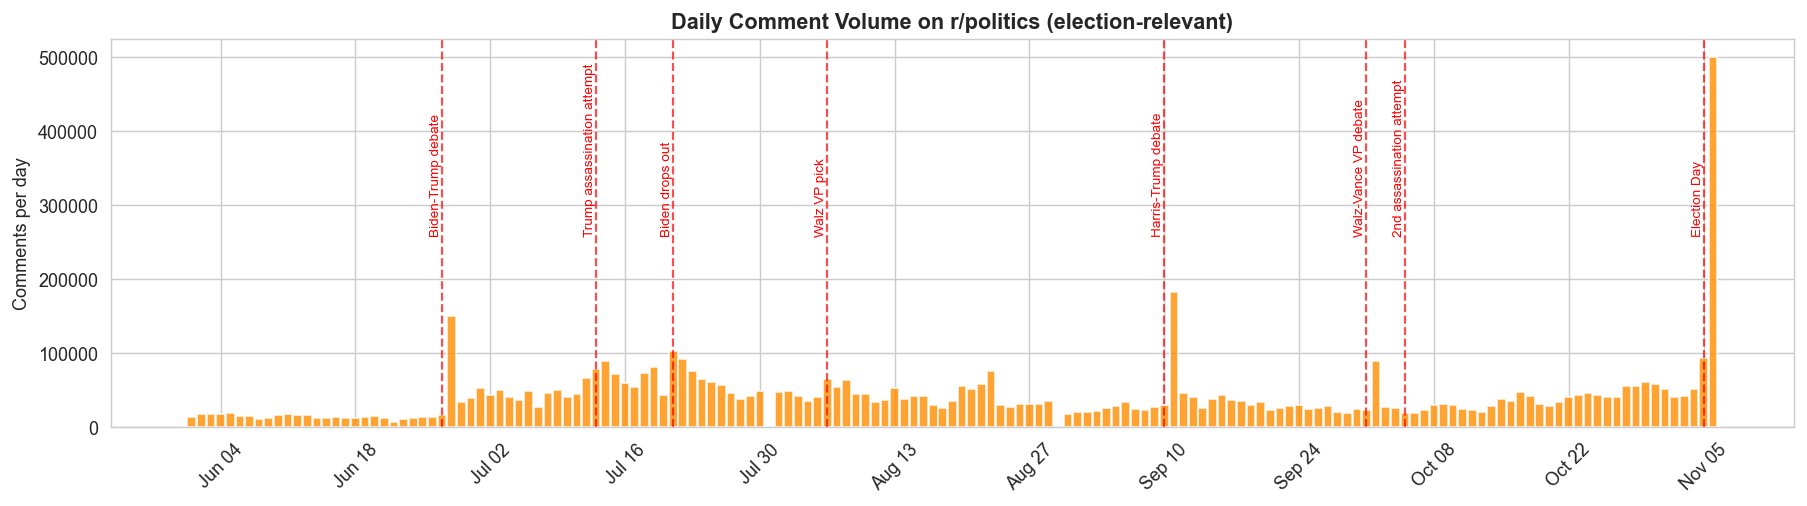

In [10]:
comments_daily = df_comments.groupby('date_day').size().reset_index(name='comments')

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(comments_daily['date_day'], comments_daily['comments'],
       color='darkorange', alpha=0.8, width=0.9)
ax.set_ylabel('Comments per day')
ax.set_title('Daily Comment Volume on r/politics (election-relevant)', fontweight='bold')

for date_str, label in EVENTS.items():
    d = pd.to_datetime(date_str)
    ax.axvline(d, color='red', linestyle='--', alpha=0.7, linewidth=1.2)
    ax.text(d, ax.get_ylim()[1] * 0.5, label, rotation=90,
            fontsize=7.5, color='red', ha='right')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

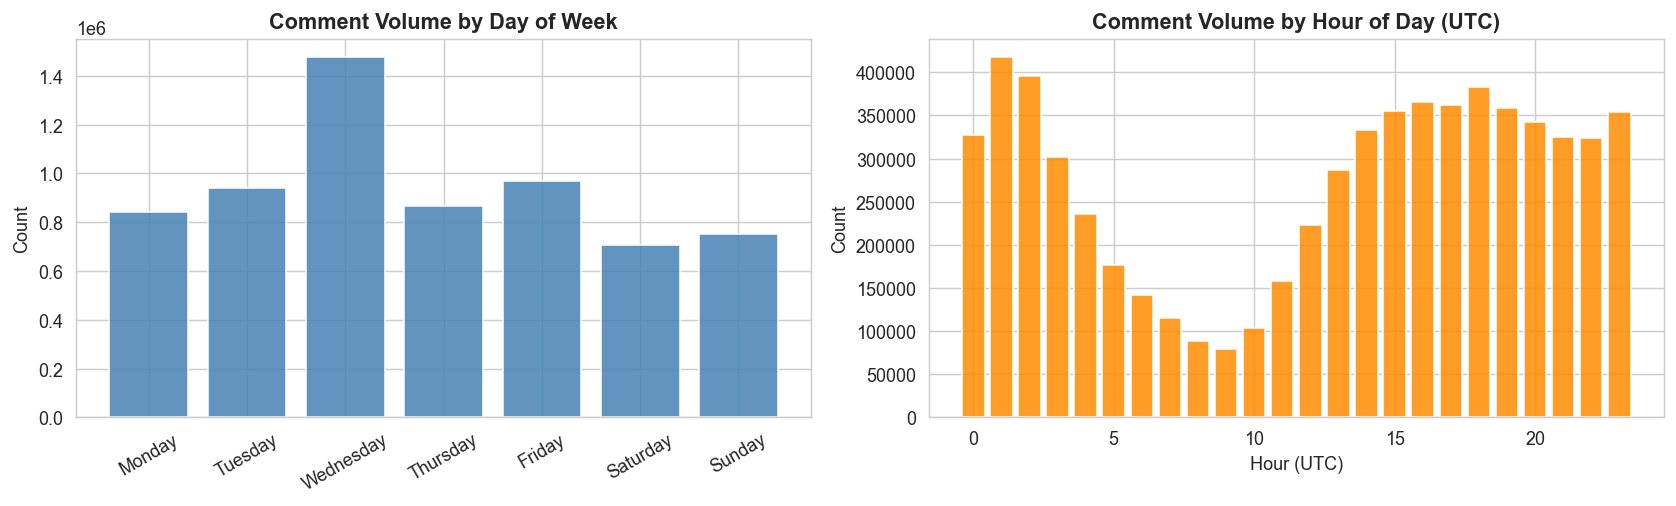

In [11]:
df_comments['hour']        = df_comments['date'].dt.hour
df_comments['day_of_week'] = df_comments['date'].dt.day_name()
DOW_ORDER = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dow_counts = df_comments['day_of_week'].value_counts().reindex(DOW_ORDER)
axes[0].bar(dow_counts.index, dow_counts.values, color='steelblue', alpha=0.85)
axes[0].set_title('Comment Volume by Day of Week', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

hour_counts = df_comments['hour'].value_counts().sort_index()
axes[1].bar(hour_counts.index, hour_counts.values, color='darkorange', alpha=0.85)
axes[1].set_title('Comment Volume by Hour of Day (UTC)', fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].set_xlabel('Hour (UTC)')

plt.tight_layout()
plt.show()


## 4. Comment Structure

Top-level vs nested ratio, and comments-per-thread distribution.

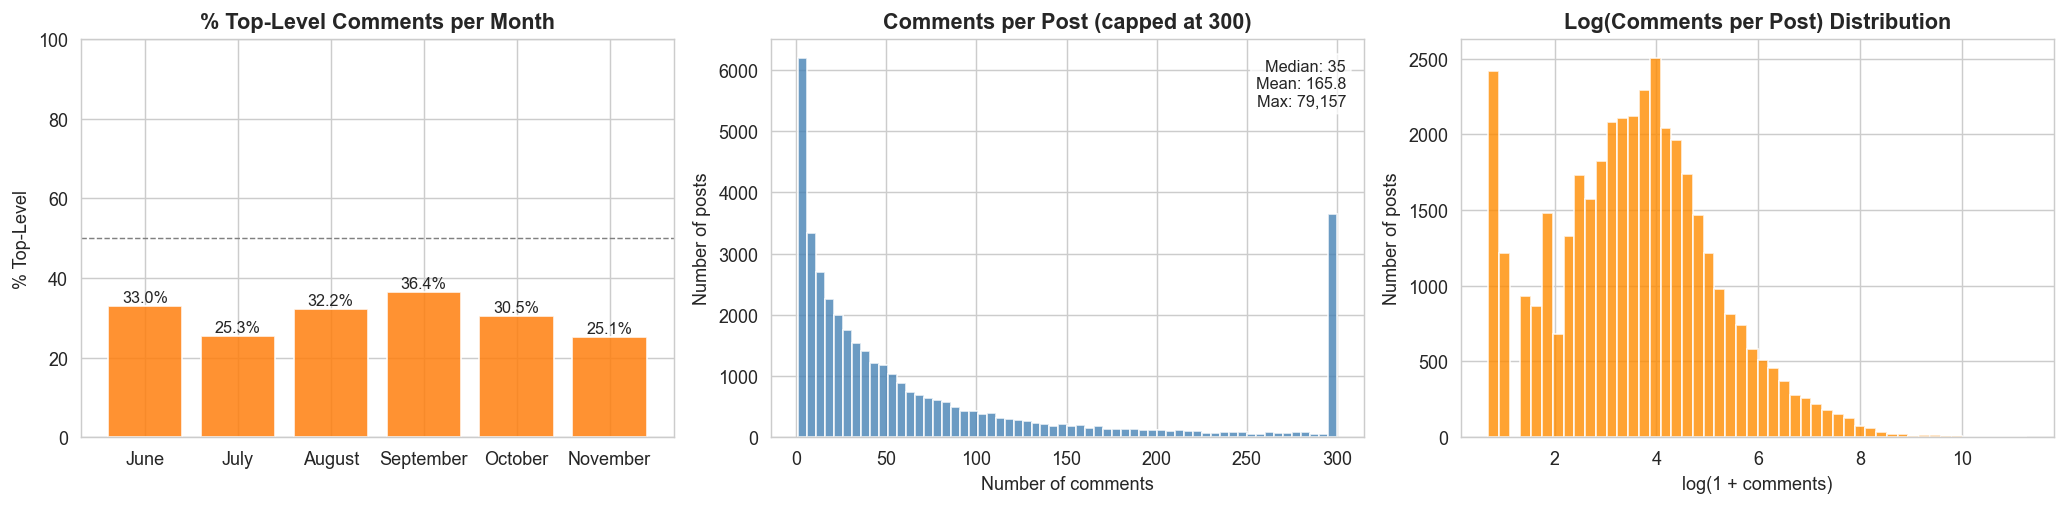

Posts with 0 comments: 0
Posts with 1-10:       9,531
Posts with 100+:       9,478
Posts with 1000+:      1,107


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

tl = df_comments.groupby('month')['is_top_level'].mean().reindex(months_present) * 100
axes[0].bar(tl.index, tl.values,
            color=['#1f77b4' if v > 50 else '#ff7f0e' for v in tl.values], alpha=0.85)
axes[0].axhline(50, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_title('% Top-Level Comments per Month', fontweight='bold')
axes[0].set_ylabel('% Top-Level')
axes[0].set_ylim(0, 100)
for i, v in enumerate(tl.values):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)

cpp = df_comments.groupby('post_id').size()
axes[1].hist(cpp.clip(upper=300), bins=60, color='steelblue', alpha=0.8, edgecolor='white')
axes[1].set_title('Comments per Post (capped at 300)', fontweight='bold')
axes[1].set_xlabel('Number of comments')
axes[1].set_ylabel('Number of posts')
axes[1].text(0.97, 0.95, f'Median: {cpp.median():.0f}\nMean: {cpp.mean():.1f}\nMax: {cpp.max():,}',
             transform=axes[1].transAxes, va='top', ha='right', fontsize=9,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

axes[2].hist(np.log1p(cpp), bins=50, color='darkorange', alpha=0.8, edgecolor='white')
axes[2].set_title('Log(Comments per Post) Distribution', fontweight='bold')
axes[2].set_xlabel('log(1 + comments)')
axes[2].set_ylabel('Number of posts')

plt.tight_layout()
plt.show()

print(f'Posts with 0 comments: {(cpp == 0).sum():,}')
print(f'Posts with 1-10:       {((cpp >= 1) & (cpp <= 10)).sum():,}')
print(f'Posts with 100+:       {(cpp >= 100).sum():,}')
print(f'Posts with 1000+:      {(cpp >= 1000).sum():,}')


## 5. Text Characteristics

Body length, vocabulary richness, top unigrams, bigrams, and trigrams.

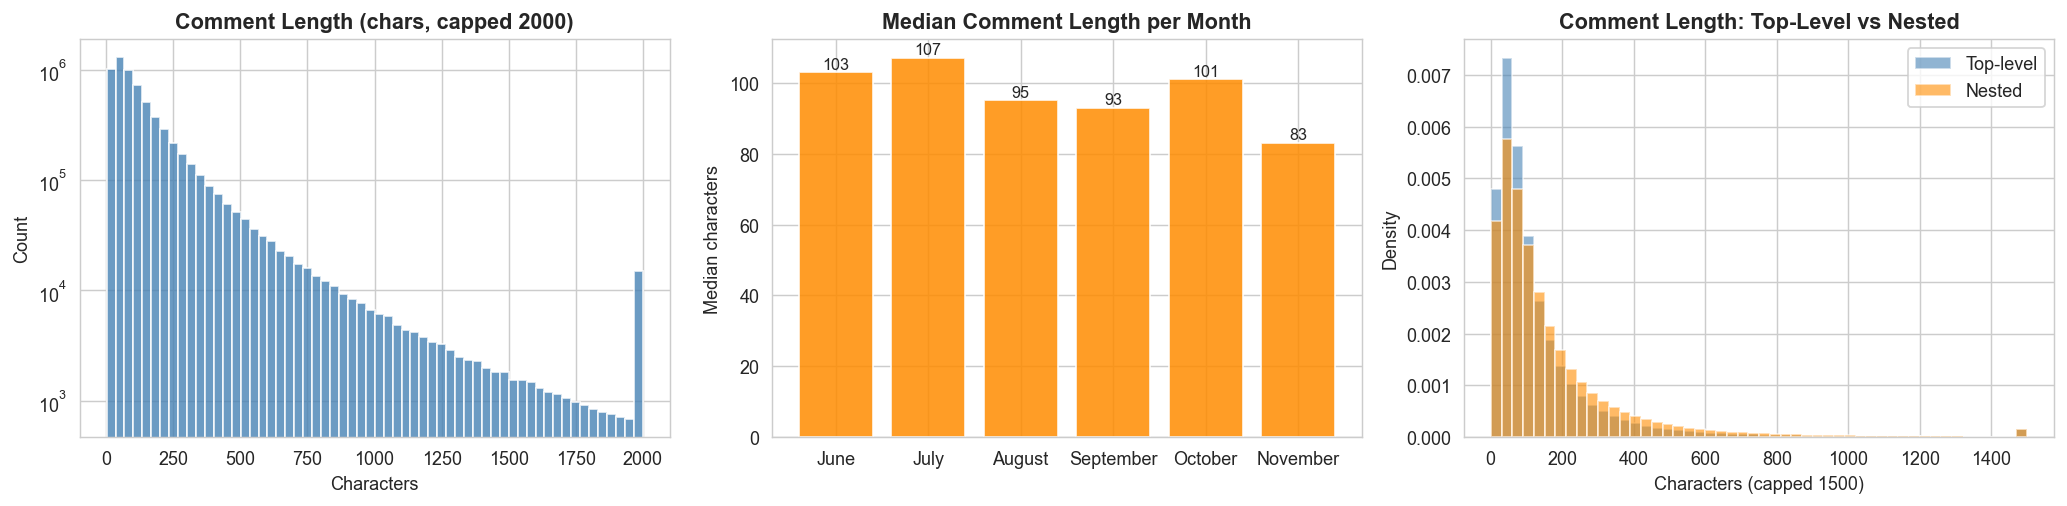

Body length percentiles:
count    6553662.0
mean         167.0
std          246.0
min            1.0
25%           49.0
50%           98.0
75%          195.0
90%          363.0
99%         1095.0
max        10000.0
Name: body_len, dtype: float64


In [13]:
df_comments['body_len'] = df_comments['body'].str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_comments['body_len'].clip(upper=2000), bins=60,
             color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title('Comment Length (chars, capped 2000)', fontweight='bold')
axes[0].set_xlabel('Characters')
axes[0].set_ylabel('Count')
axes[0].set_yscale('log')

med_len = df_comments.groupby('month')['body_len'].median().reindex(months_present)
axes[1].bar(med_len.index, med_len.values, color='darkorange', alpha=0.85)
axes[1].set_title('Median Comment Length per Month', fontweight='bold')
axes[1].set_ylabel('Median characters')
for i, v in enumerate(med_len.values):
    axes[1].text(i, v + 1, f'{v:.0f}', ha='center', fontsize=9)

tl_len   = df_comments[df_comments['is_top_level']]['body_len'].clip(upper=1500)
nest_len = df_comments[~df_comments['is_top_level']]['body_len'].clip(upper=1500)
axes[2].hist(tl_len,   bins=50, alpha=0.6, color='steelblue',  label='Top-level', density=True)
axes[2].hist(nest_len, bins=50, alpha=0.6, color='darkorange', label='Nested',     density=True)
axes[2].set_title('Comment Length: Top-Level vs Nested', fontweight='bold')
axes[2].set_xlabel('Characters (capped 1500)')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.show()

print('Body length percentiles:')
print(df_comments['body_len'].describe(percentiles=[.25,.5,.75,.90,.99]).round(0))


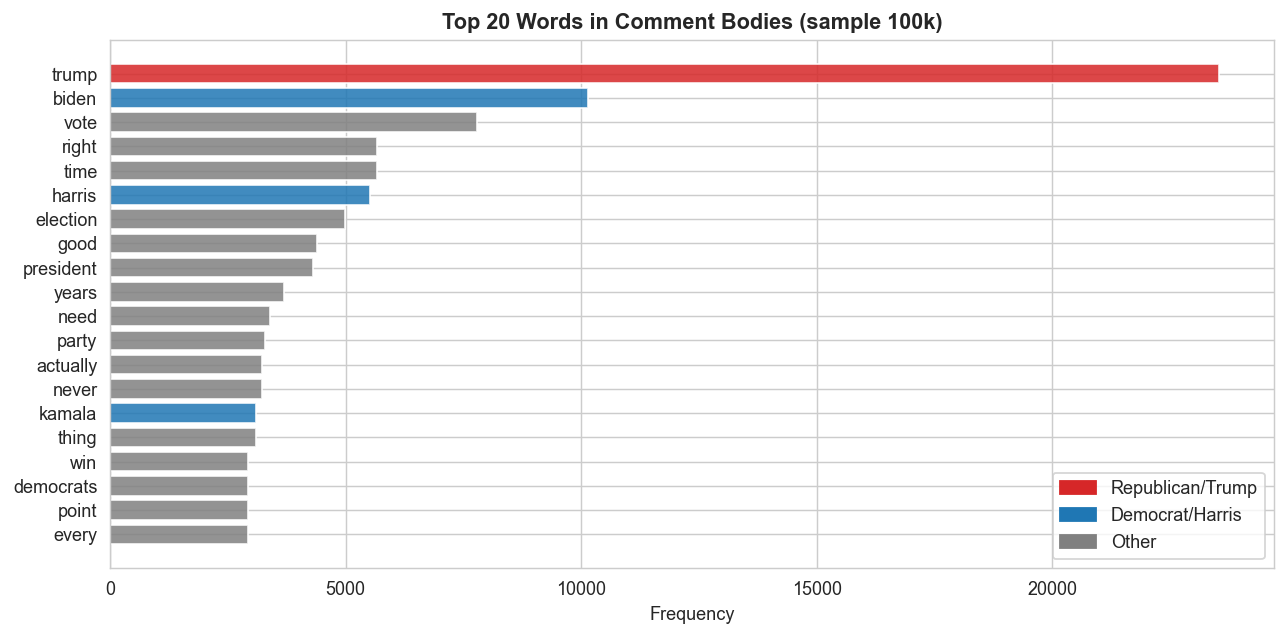

In [14]:
stop_words = set(stopwords.words('english'))
extra_stops = {'would', 'could', 'also', 'one', 'get', 'like', 'think', 'people',
               'make', 'know', 'see', 'even', 'still', 'say', 'said', 'says',
               'amp', 'much', 'way', 'got', 'well', 'going', 'want', 'really',
               'us', 'im', 'dont', 'its', 'thats', 'ive', 'youre', 'hes', 'shes',
               'http', 'https', 'www', 'com', 'subreddit', 'reddit'}
stop_words |= extra_stops

def tokenize(text):
    return [w for w in re.findall(r'\b[a-z]{3,}\b', str(text).lower())
            if w not in stop_words]

sample_bodies = df_comments['body'].sample(min(100_000, len(df_comments)), random_state=42)
all_tokens = []
for t in sample_bodies:
    all_tokens.extend(tokenize(t))

unigrams = Counter(all_tokens).most_common(20)
words, counts = zip(*unigrams)
colors = ['#d62728' if w in ['trump', 'republican', 'gop', 'maga'] else
          '#1f77b4' if w in ['harris', 'democrat', 'democratic', 'biden', 'kamala', 'walz'] else
          'gray' for w in words]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(words[::-1], counts[::-1], color=colors[::-1], alpha=0.85)
ax.set_title('Top 20 Words in Comment Bodies (sample 100k)', fontweight='bold')
ax.set_xlabel('Frequency')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#d62728', label='Republican/Trump'),
                   Patch(color='#1f77b4', label='Democrat/Harris'),
                   Patch(color='gray', label='Other')], loc='lower right')
plt.tight_layout()
plt.show()


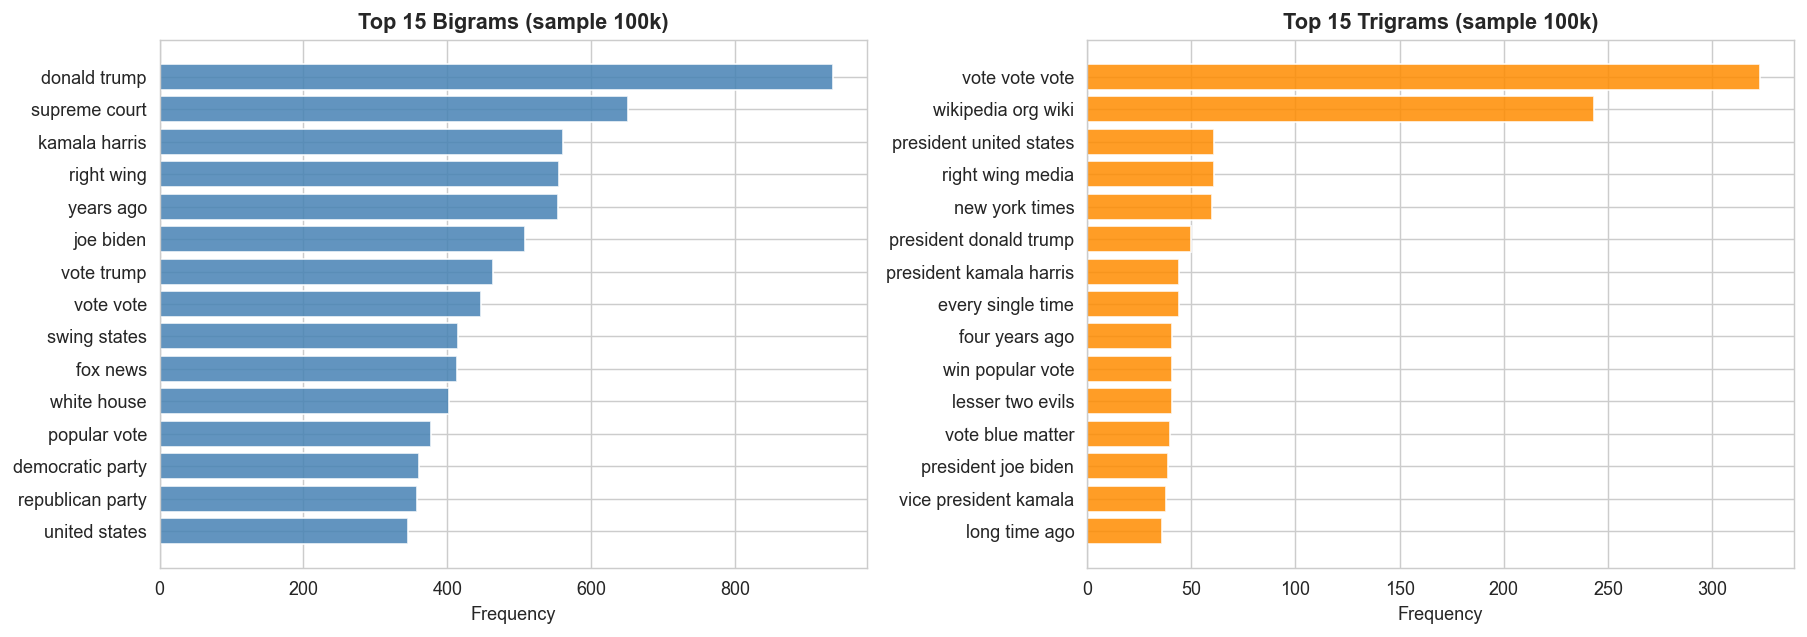

In [15]:
bigrams  = Counter(ngrams(all_tokens, 2)).most_common(15)
trigrams = Counter(ngrams(all_tokens, 3)).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bg_labels, bg_counts = zip(*[(' '.join(g), c) for g, c in bigrams])
axes[0].barh(bg_labels[::-1], bg_counts[::-1], color='steelblue', alpha=0.85)
axes[0].set_title('Top 15 Bigrams (sample 100k)', fontweight='bold')
axes[0].set_xlabel('Frequency')

tg_labels, tg_counts = zip(*[(' '.join(g), c) for g, c in trigrams])
axes[1].barh(tg_labels[::-1], tg_counts[::-1], color='darkorange', alpha=0.85)
axes[1].set_title('Top 15 Trigrams (sample 100k)', fontweight='bold')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()


In [16]:
print('=== Vocabulary Size per Month (unique words, sample 20k/month) ===')
for month in months_present:
    subset = df_comments[df_comments['month'] == month]['body'].sample(
        min(20_000, (df_comments['month'] == month).sum()), random_state=42)
    vocab = set()
    for t in subset:
        vocab.update(tokenize(t))
    print(f'  {month:12s}: {len(vocab):,} unique words')


=== Vocabulary Size per Month (unique words, sample 20k/month) ===
  June        : 21,907 unique words
  July        : 21,195 unique words
  August      : 22,483 unique words
  September   : 22,071 unique words
  October     : 22,694 unique words
  November    : 19,011 unique words


## 6. Candidate Framing

Mention rates, co-occurrence, score by candidate, and top words per candidate.

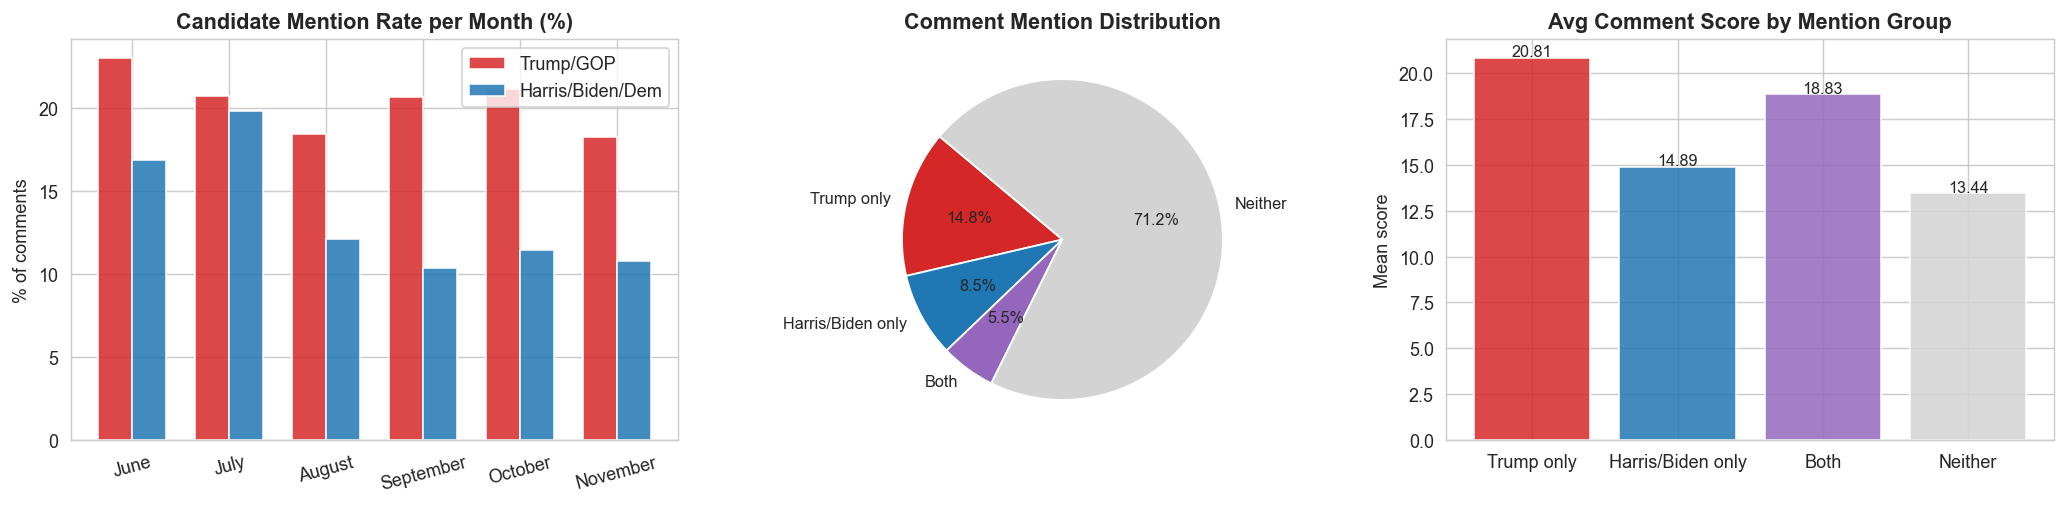

  Trump only          : 966,904 comments
  Harris/Biden only   : 558,092 comments
  Both                : 362,546 comments
  Neither             : 4,666,120 comments


In [ ]:
df_comments['mentions_trump']        = df_comments['body'].str.contains(
    r'\b(trump|donald|maga|republican|gop)\b', case=False, regex=True, na=False)
df_comments['mentions_harris/biden'] = df_comments['body'].str.contains(
    r'\b(harris|kamala|biden|democrat|walz)\b', case=False, regex=True, na=False)

mention_rates = df_comments.groupby('month')[['mentions_trump','mentions_harris/biden']].mean() * 100
mention_rates = mention_rates.reindex(months_present)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

x = range(len(mention_rates))
w = 0.35
axes[0].bar([i - w/2 for i in x], mention_rates['mentions_trump'],
            width=w, color='#d62728', alpha=0.85, label='Trump/GOP')
axes[0].bar([i + w/2 for i in x], mention_rates['mentions_harris/biden'],
            width=w, color='#1f77b4', alpha=0.85, label='Harris/Biden/Dem')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(mention_rates.index, rotation=15)
axes[0].set_title('Candidate Mention Rate per Month (%)', fontweight='bold')
axes[0].set_ylabel('% of comments')
axes[0].legend()

only_trump        = (df_comments['mentions_trump'] & ~df_comments['mentions_harris/biden']).sum()
only_harris_biden = (~df_comments['mentions_trump'] & df_comments['mentions_harris/biden']).sum()
both              = (df_comments['mentions_trump'] & df_comments['mentions_harris/biden']).sum()
neither           = (~df_comments['mentions_trump'] & ~df_comments['mentions_harris/biden']).sum()
labels_pie = ['Trump only', 'Harris/Biden only', 'Both', 'Neither']
sizes      = [only_trump, only_harris_biden, both, neither]
colors_pie = ['#d62728', '#1f77b4', '#9467bd', 'lightgray']
axes[1].pie(sizes, labels=labels_pie, colors=colors_pie, autopct='%1.1f%%',
            startangle=140, textprops={'fontsize': 9})
axes[1].set_title('Comment Mention Distribution', fontweight='bold')

groups = {
    'Trump only':       df_comments[ df_comments['mentions_trump'] & ~df_comments['mentions_harris/biden']]['score'],
    'Harris/Biden only':df_comments[~df_comments['mentions_trump'] &  df_comments['mentions_harris/biden']]['score'],
    'Both':             df_comments[ df_comments['mentions_trump'] &  df_comments['mentions_harris/biden']]['score'],
    'Neither':          df_comments[~df_comments['mentions_trump'] & ~df_comments['mentions_harris/biden']]['score'],
}
means = {k: v.mean() for k, v in groups.items()}
bars = axes[2].bar(means.keys(), means.values(), color=colors_pie, alpha=0.85)
axes[2].set_title('Avg Comment Score by Mention Group', fontweight='bold')
axes[2].set_ylabel('Mean score')
for bar, val in zip(bars, means.values()):
    axes[2].text(bar.get_x() + bar.get_width()/2, val + 0.1, f'{val:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

for k, v in groups.items():
    print(f'  {k:20s}: {len(v):,} comments')

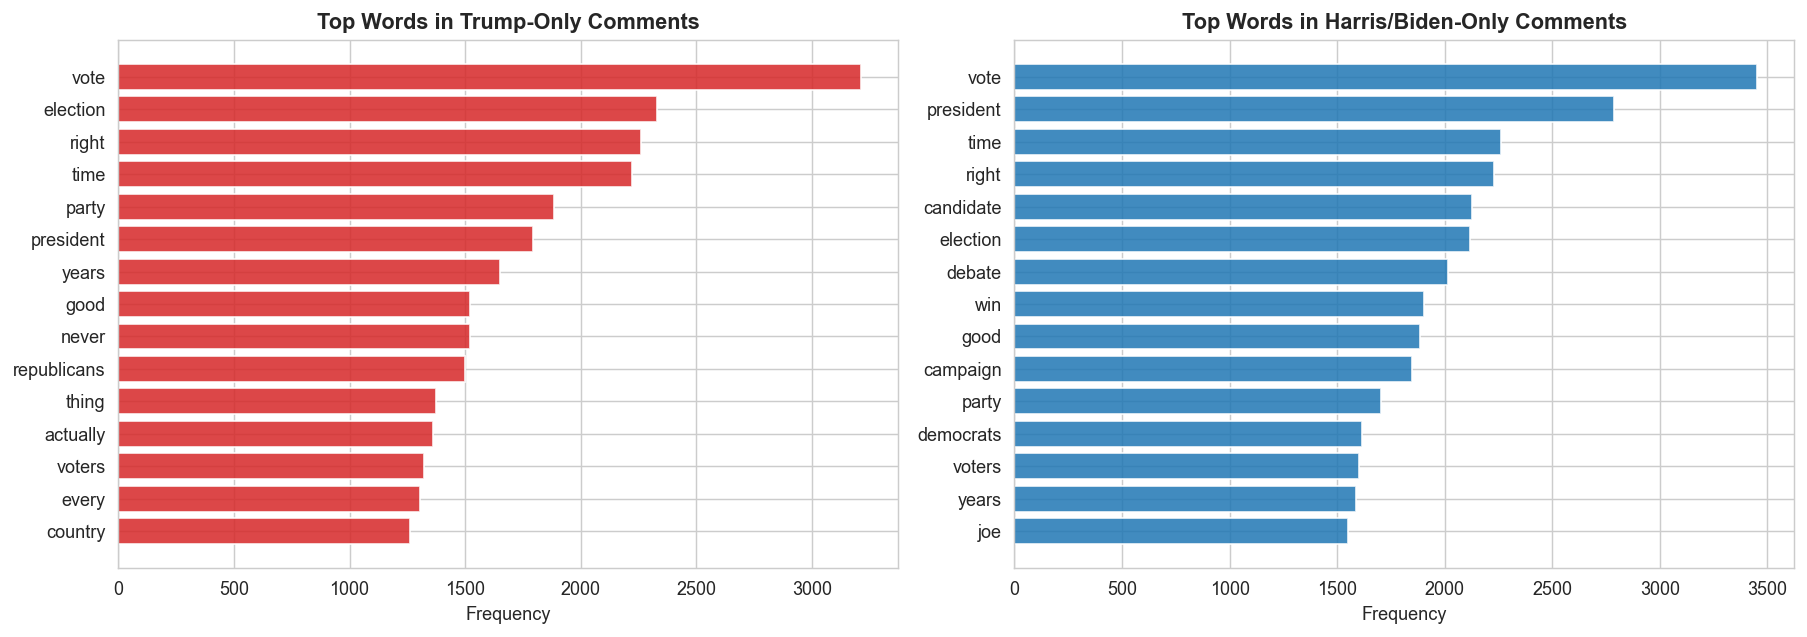

In [18]:
trump_extra  = {'trump', 'donald', 'maga', 'republican', 'gop'}
harris_extra = {'harris', 'kamala', 'biden', 'democrat', 'democratic', 'walz'}
combined_stops = stop_words | trump_extra | harris_extra

trump_sample  = df_comments[ df_comments['mentions_trump'] & ~df_comments['mentions_harris/biden']]['body'].sample(min(30_000, df_comments['mentions_trump'].sum()), random_state=42)
harris_sample = df_comments[~df_comments['mentions_trump'] &  df_comments['mentions_harris/biden']]['body'].sample(min(30_000, df_comments['mentions_harris/biden'].sum()), random_state=42)

trump_words, harris_words = [], []
for t in trump_sample:  trump_words.extend([w for w in tokenize(t) if w not in combined_stops])
for t in harris_sample: harris_words.extend([w for w in tokenize(t) if w not in combined_stops])

top_trump  = Counter(trump_words).most_common(15)
top_harris = Counter(harris_words).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tw, tc = zip(*top_trump)
hw, hc = zip(*top_harris)
axes[0].barh(tw[::-1], tc[::-1], color='#d62728', alpha=0.85)
axes[0].set_title('Top Words in Trump-Only Comments', fontweight='bold')
axes[0].set_xlabel('Frequency')
axes[1].barh(hw[::-1], hc[::-1], color='#1f77b4', alpha=0.85)
axes[1].set_title('Top Words in Harris/Biden-Only Comments', fontweight='bold')
axes[1].set_xlabel('Frequency')
plt.tight_layout()
plt.show()

## 7. Score & Engagement

Score distribution, top-level vs nested, and most engaging comments.

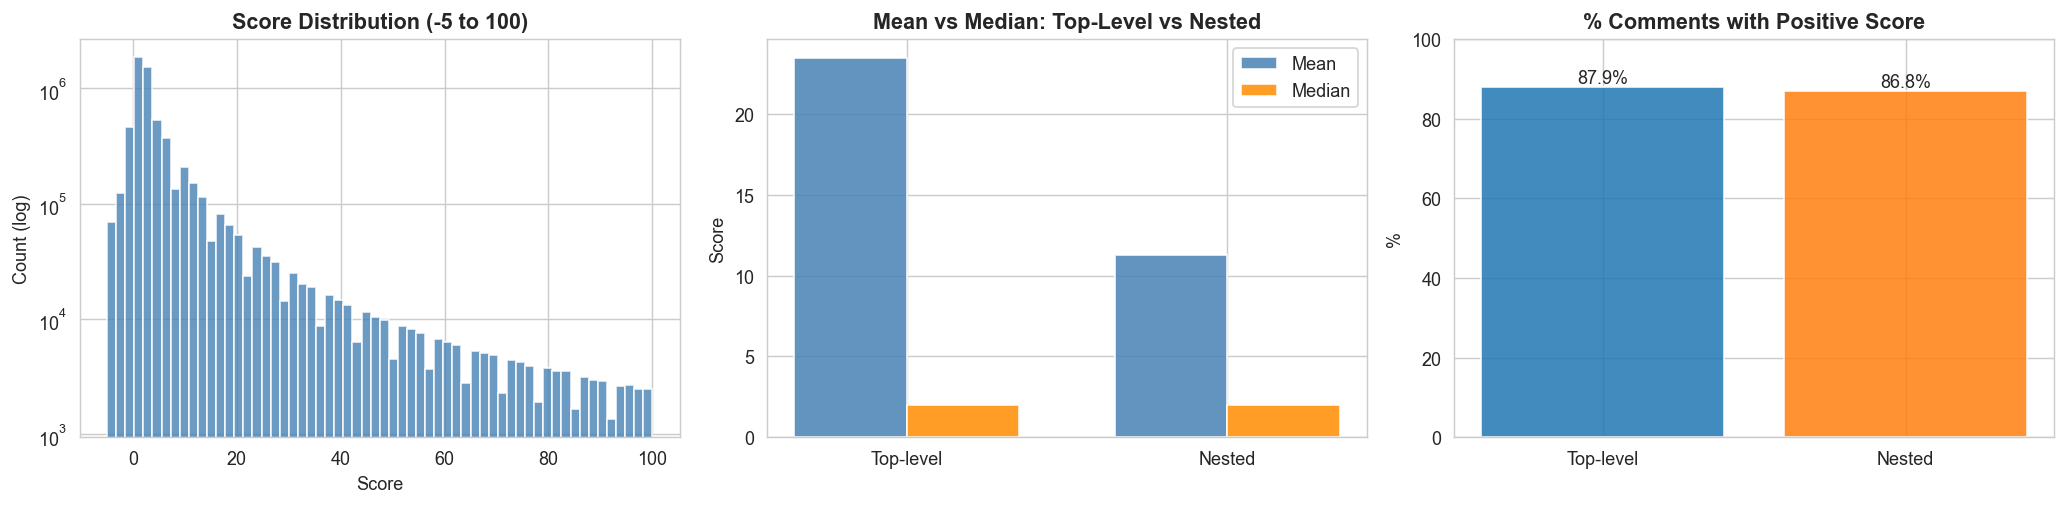

In [19]:
tl_scores   = df_comments[df_comments['is_top_level']]['score']
nest_scores = df_comments[~df_comments['is_top_level']]['score']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

meaningful = df_comments[(df_comments['score'] >= -5) & (df_comments['score'] <= 100)]
axes[0].hist(meaningful['score'], bins=60, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title('Score Distribution (-5 to 100)', fontweight='bold')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Count (log)')
axes[0].set_yscale('log')

groups_score = {'Top-level': tl_scores, 'Nested': nest_scores}
means   = {k: v.mean() for k, v in groups_score.items()}
medians = {k: v.median() for k, v in groups_score.items()}
x, w = range(2), 0.35
axes[1].bar([i-w/2 for i in x], means.values(),   width=w, color='steelblue',  alpha=0.85, label='Mean')
axes[1].bar([i+w/2 for i in x], medians.values(), width=w, color='darkorange', alpha=0.85, label='Median')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(groups_score.keys())
axes[1].set_title('Mean vs Median: Top-Level vs Nested', fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].legend()

pos_pct = {k: (v > 0).mean() * 100 for k, v in groups_score.items()}
bars = axes[2].bar(pos_pct.keys(), pos_pct.values(), color=['#1f77b4','#ff7f0e'], alpha=0.85)
axes[2].set_title('% Comments with Positive Score', fontweight='bold')
axes[2].set_ylabel('%')
axes[2].set_ylim(0, 100)
for bar, val in zip(bars, pos_pct.values()):
    axes[2].text(bar.get_x()+bar.get_width()/2, val+1, f'{val:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()


In [20]:
print('=== Top 10 Highest-Scored Comments ===')
for _, row in df_comments.nlargest(10, 'score')[['score','vader_label','body']].iterrows():
    print(f"  [score={row['score']:,}] [{row['vader_label']}] {str(row['body'])[:100]}")

print('\n=== Top 10 Most Downvoted Comments ===')
for _, row in df_comments.nsmallest(10, 'score')[['score','vader_label','body']].iterrows():
    print(f"  [score={row['score']:,}] [{row['vader_label']}] {str(row['body'])[:100]}")


=== Top 10 Highest-Scored Comments ===
  [score=31,352] [positive] >Shannon Bream asked Buttigieg — the Transportation Secretary who has been floated as Vice President
  [score=29,534] [neutral] This may be the most blatant statement of being bought from a politician that I’ve ever heard.
  [score=22,487] [negative] Democrats own guns. They just aren’t weird about it.
  [score=22,419] [neutral] The past four weeks have been the longest 20 years of my life.
  [score=22,324] [positive] >“Well, hold on,” she said, holding out her hand as if to placate the crowd in Eau Claire, Wisc. “Yo
  [score=22,018] [positive] Billionaires being this reluctant to endorse Kamala should be more motivation to vote for her than a
  [score=21,107] [negative] I wonder how the timeline that lost the two presidential candidates within a week is doing
  [score=20,894] [positive] Wow, can’t believe the GOP is now running the oldest nominee for president in American history
  [score=20,663] [neutral] They need to

## 8. VADER Silver Labels

Labels pre-computed in `VADER_Labeling.ipynb`. Distribution, validation, and cross-analysis.

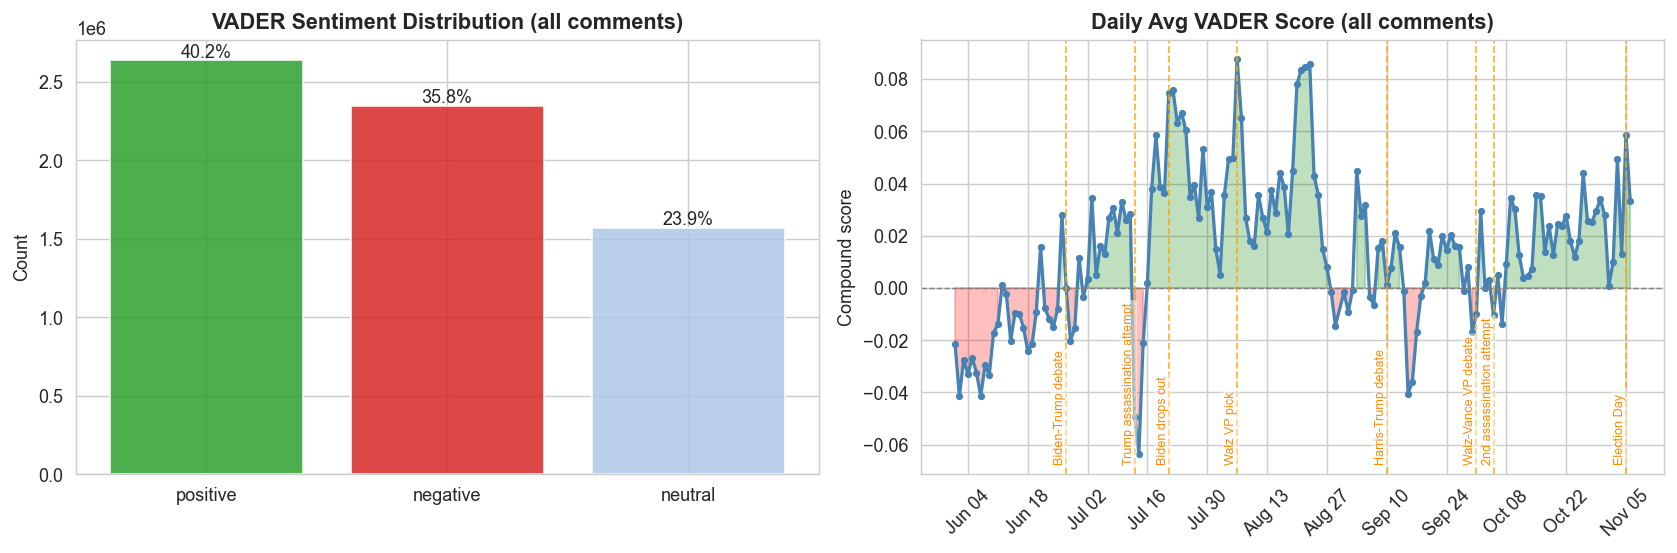

In [21]:
colors_map = {'positive': '#2ca02c', 'negative': '#d62728', 'neutral': '#aec7e8'}
label_counts = df_comments['vader_label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(label_counts.index, label_counts.values,
            color=[colors_map[l] for l in label_counts.index], alpha=0.85)
axes[0].set_title('VADER Sentiment Distribution (all comments)', fontweight='bold')
axes[0].set_ylabel('Count')
for i, (label, count) in enumerate(label_counts.items()):
    axes[0].text(i, count + 20000, f'{count/len(df_comments)*100:.1f}%', ha='center', fontsize=10)

daily_sent = df_comments.groupby('date_day')['vader_score'].mean().reset_index()
axes[1].plot(daily_sent['date_day'], daily_sent['vader_score'],
             color='steelblue', linewidth=1.8, marker='o', markersize=3)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].fill_between(daily_sent['date_day'], daily_sent['vader_score'], 0,
                     where=(daily_sent['vader_score'] >= 0), alpha=0.25, color='green')
axes[1].fill_between(daily_sent['date_day'], daily_sent['vader_score'], 0,
                     where=(daily_sent['vader_score'] < 0), alpha=0.25, color='red')
axes[1].set_title('Daily Avg VADER Score (all comments)', fontweight='bold')
axes[1].set_ylabel('Compound score')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
for date_str, label in EVENTS.items():
    d = pd.to_datetime(date_str)
    axes[1].axvline(d, color='orange', linestyle='--', alpha=0.8, linewidth=1)
    axes[1].text(d, axes[1].get_ylim()[1] * -0.7, label, rotation=90,
                 fontsize=7, color='darkorange', ha='right',
                 bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none",alpha=0.45)
        )
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45)
plt.tight_layout()
plt.subplots_adjust(top=1)
plt.show()


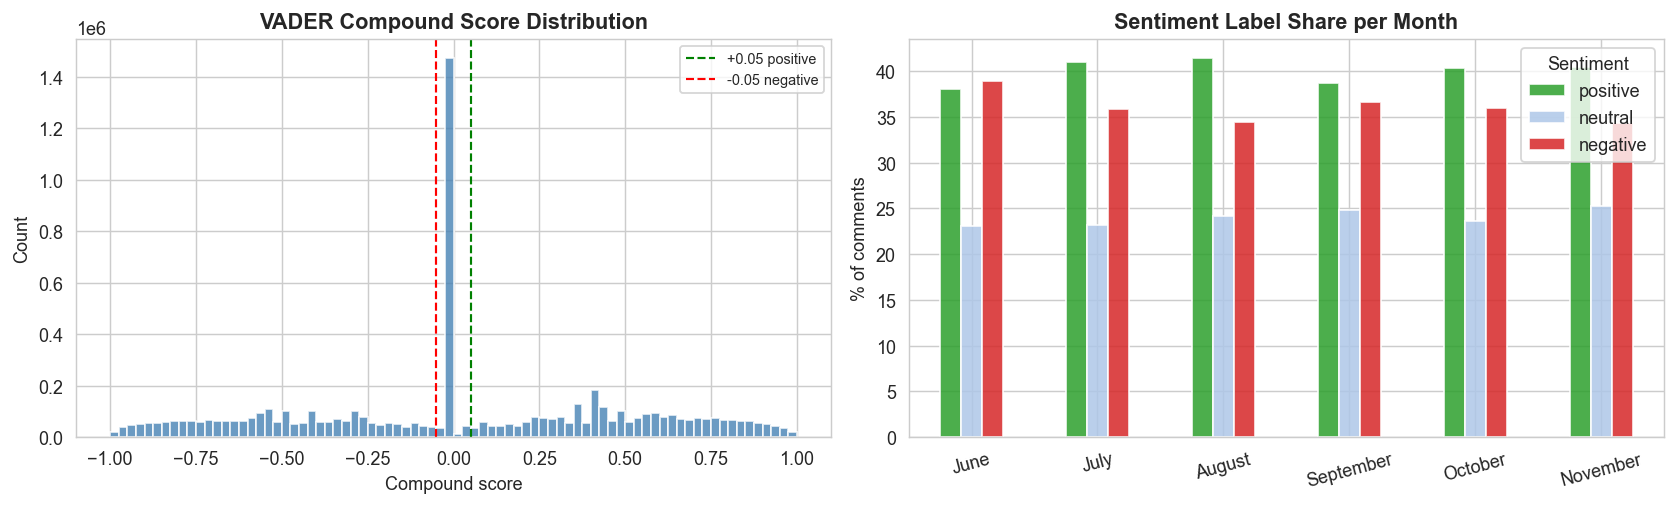

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df_comments['vader_score'], bins=80, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].axvline(0.05,  color='green', linestyle='--', linewidth=1.2, label='+0.05 positive')
axes[0].axvline(-0.05, color='red',   linestyle='--', linewidth=1.2, label='-0.05 negative')
axes[0].set_title('VADER Compound Score Distribution', fontweight='bold')
axes[0].set_xlabel('Compound score')
axes[0].set_ylabel('Count')
axes[0].legend(fontsize=8)

month_labels = df_comments.groupby('month')['vader_label'].value_counts(normalize=True).unstack().fillna(0) * 100
month_labels = month_labels.reindex([m for m in MONTH_ORDER if m in month_labels.index])
month_labels[['positive','neutral','negative']].plot(
    kind='bar', ax=axes[1], color=['#2ca02c','#aec7e8','#d62728'], alpha=0.85)
axes[1].set_title('Sentiment Label Share per Month', fontweight='bold')
axes[1].set_ylabel('% of comments')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='Sentiment')

plt.tight_layout()
plt.show()


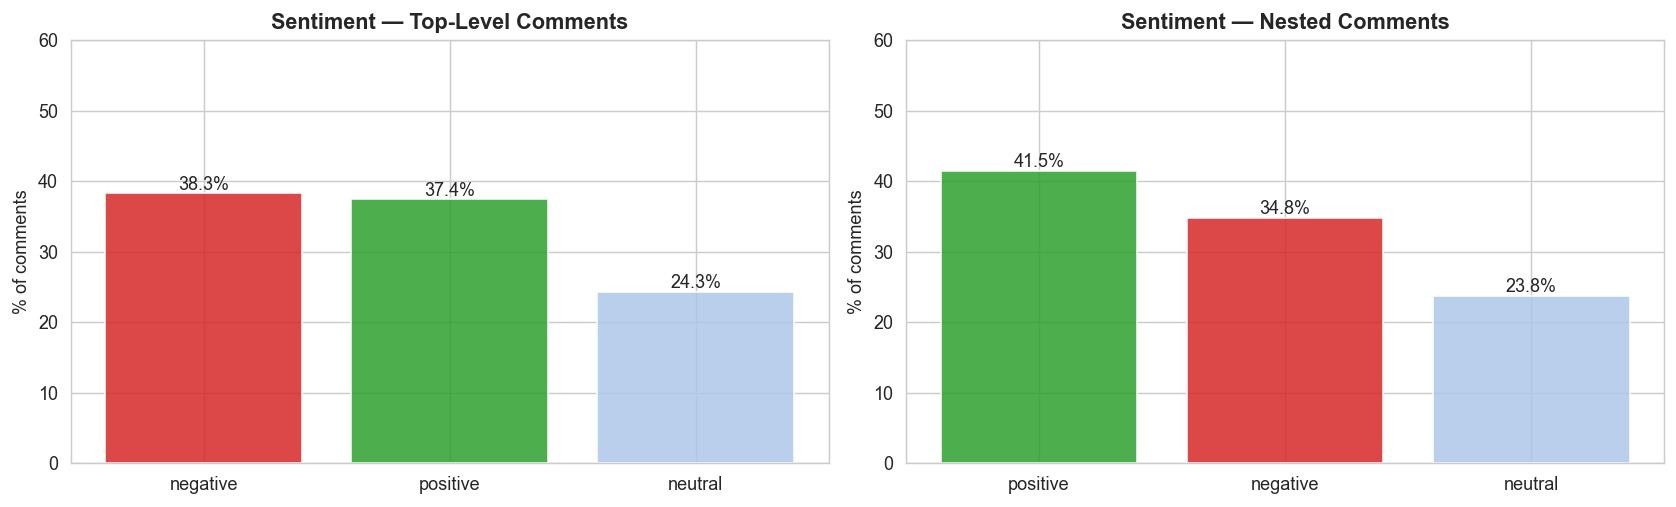

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, level, label in zip(axes, [True, False], ['Top-Level', 'Nested']):
    lc = df_comments[df_comments['is_top_level'] == level]['vader_label'].value_counts(normalize=True) * 100
    ax.bar(lc.index, lc.values, color=[colors_map.get(l, 'gray') for l in lc.index], alpha=0.85)
    ax.set_title(f'Sentiment — {label} Comments', fontweight='bold')
    ax.set_ylabel('% of comments')
    ax.set_ylim(0, 60)
    for i, (lbl, val) in enumerate(lc.items()):
        ax.text(i, val + 0.5, f'{val:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()


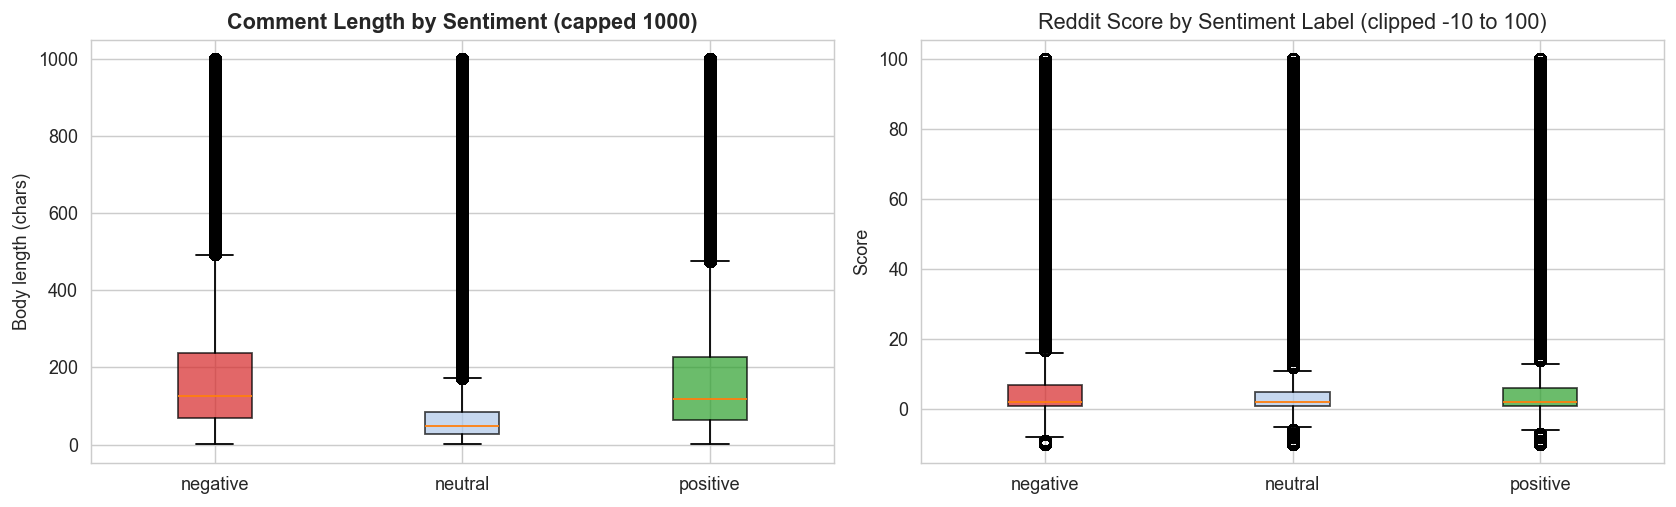

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

order = ['negative', 'neutral', 'positive']
data  = [df_comments[df_comments['vader_label'] == l]['body_len'].clip(upper=1000) for l in order]
bp = axes[0].boxplot(data, labels=order, patch_artist=True)
for patch, color in zip(bp['boxes'], ['#d62728', '#aec7e8', '#2ca02c']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[0].set_title('Comment Length by Sentiment (capped 1000)', fontweight='bold')
axes[0].set_ylabel('Body length (chars)')

score_data = [df_comments[df_comments['vader_label'] == l]['score'].clip(-10, 100) for l in order]
bp2 = axes[1].boxplot(score_data, labels=order, patch_artist=True)
for patch, color in zip(bp2['boxes'], ['#d62728', '#aec7e8', '#2ca02c']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].set_title('Reddit Score by Sentiment Label (clipped -10 to 100)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()


In [25]:
print('=== Silver Label Sanity Check ===')
for label in ['positive', 'negative', 'neutral']:
    subset = df_comments[df_comments['vader_label'] == label]
    print(f'\n--- {label.upper()} (sample 3) ---')
    for _, row in subset.sample(3, random_state=42).iterrows():
        print(f'  [{row["vader_score"]:+.3f}] {str(row["body"])[:110]}')


=== Silver Label Sanity Check ===

--- POSITIVE (sample 3) ---
  [+0.979] I buy that they're in a tough spot.  But to suggest that there's no difference between the party that has [alr
  [+0.718] Doesn’t even have to be the feds owning it, just invest in it with specific guidelines in place to make sure i
  [+0.421] This assessment makes sense if the intended audience likes tiki torches and hooded white robes.

--- NEGATIVE (sample 3) ---
  [-0.678] Why does comparing you to an animal upset you so much? Why do you think so lowly of animals?
  [-0.077] My boomer aunt from PA once asked me if Indians in CA still live in teepees. She was serious.
  [-0.764] Uncomfortable truth for 99% of this subreddit. Any time anyone would question ANYTHING that didn't fall 100% i

--- NEUTRAL (sample 3) ---
  [+0.000] You’re so edgy
  [+0.000] 538 is a completely different model
  [+0.000] Just did $25 myself. We're not going back!!!


## 9. Candidate Sentiment Over Time

Daily VADER scores for Trump vs Harris comments, sentiment gap, and event zoom-ins.

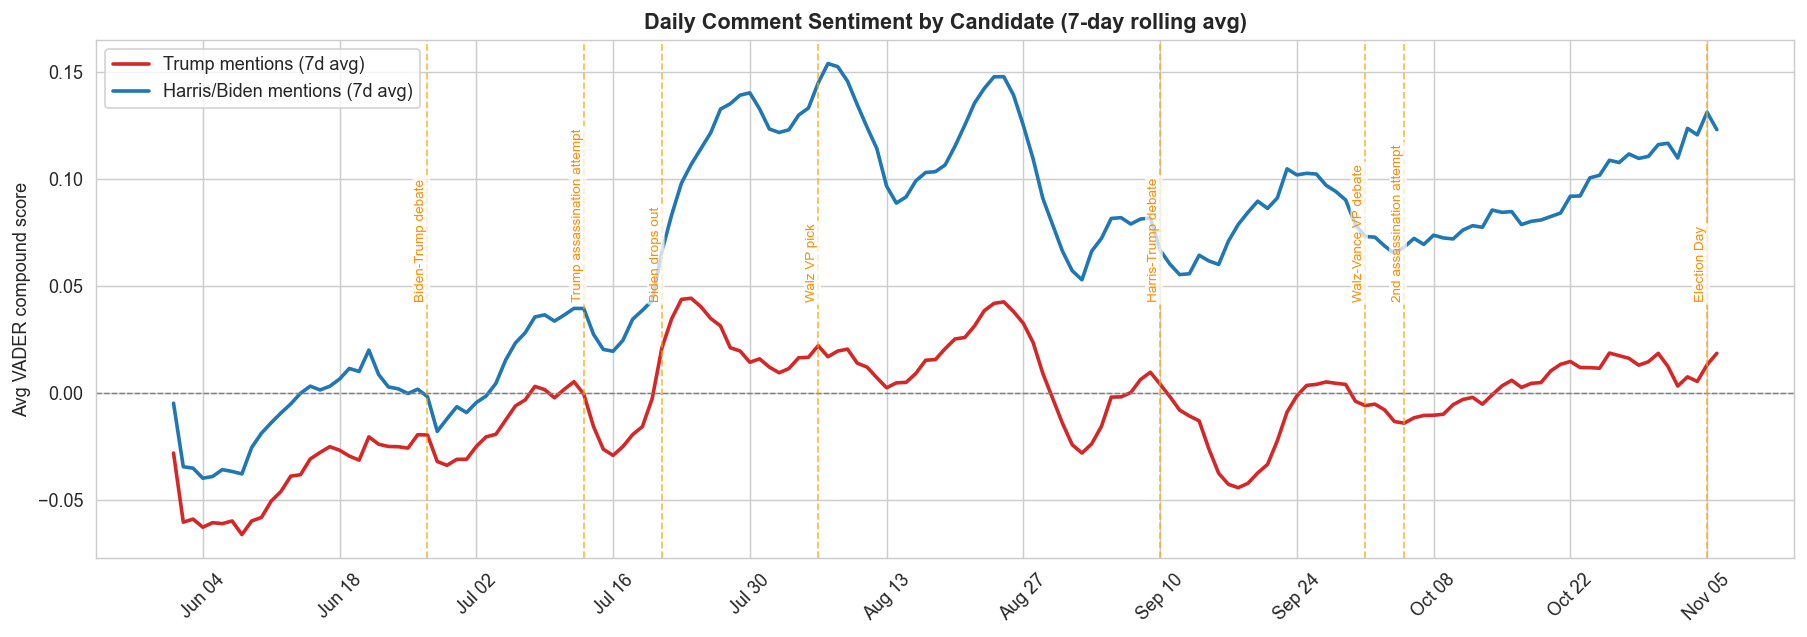

Trump-mention comments:  1,329,450
Harris/Biden-mention comments: 920,638


In [26]:
trump_daily  = df_comments[df_comments['mentions_trump']].groupby('date_day')['vader_score'].mean().reset_index()
harris_biden_daily = df_comments[df_comments['mentions_harris/biden']].groupby('date_day')['vader_score'].mean().reset_index()

trump_daily  = trump_daily.set_index('date_day').rolling('7D').mean().reset_index()
harris_biden_daily = harris_biden_daily.set_index('date_day').rolling('7D').mean().reset_index()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(trump_daily['date_day'],  trump_daily['vader_score'],
        color='#d62728', linewidth=2, label='Trump mentions (7d avg)')
ax.plot(harris_biden_daily['date_day'], harris_biden_daily['vader_score'],
        color='#1f77b4', linewidth=2, label='Harris/Biden mentions (7d avg)')
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Daily Comment Sentiment by Candidate (7-day rolling avg)', fontweight='bold')
ax.set_ylabel('Avg VADER compound score')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
for date_str, label in EVENTS.items():
    d = pd.to_datetime(date_str)
    ax.axvline(d, color='orange', linestyle='--', alpha=0.7, linewidth=1)
    ax.text(d, 0.5, label,transform=ax.get_xaxis_transform(), rotation=90,
            fontsize=7.5, color='darkorange', ha='right',
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none",alpha=0.75)
            )
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f'Trump-mention comments:  {df_comments["mentions_trump"].sum():,}')
print(f'Harris/Biden-mention comments: {df_comments["mentions_harris/biden"].sum():,}')


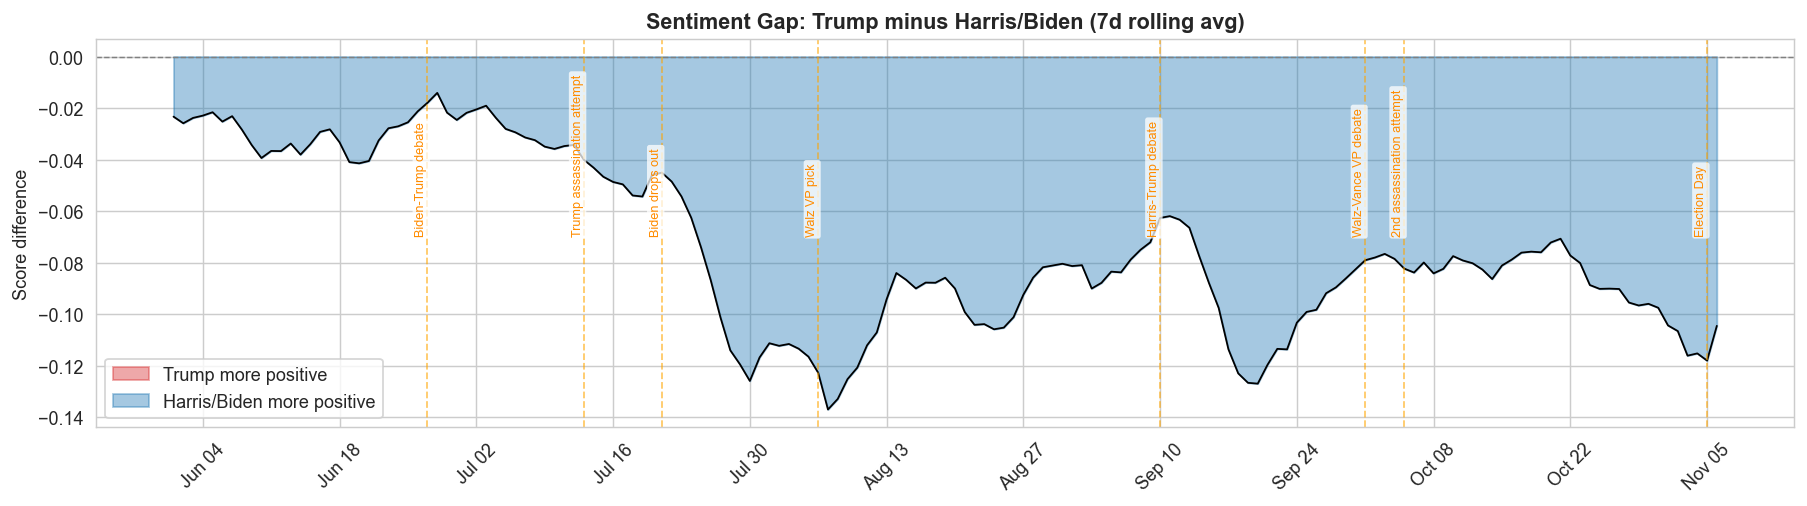

In [27]:
trump_d  = df_comments[df_comments['mentions_trump']].groupby('date_day')['vader_score'].mean()
harris_d = df_comments[df_comments['mentions_harris/biden']].groupby('date_day')['vader_score'].mean()
gap = (trump_d - harris_d).dropna().rolling('7D').mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(gap.index, gap.values, 0,
                where=(gap.values >= 0), color='#d62728', alpha=0.4, label='Trump more positive')
ax.fill_between(gap.index, gap.values, 0,
                where=(gap.values < 0),  color='#1f77b4', alpha=0.4, label='Harris/Biden more positive')
ax.plot(gap.index, gap.values, color='black', linewidth=1)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Sentiment Gap: Trump minus Harris/Biden (7d rolling avg)', fontweight='bold')
ax.set_ylabel('Score difference')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
for date_str, label in EVENTS.items():
    d = pd.to_datetime(date_str)
    ax.axvline(d, color='orange', linestyle='--', alpha=0.6, linewidth=1)
    ax.text(d, 0.5, label,transform=ax.get_xaxis_transform(), rotation=90, fontsize=7, color='darkorange', ha='right',
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
                            edgecolor="none",alpha=0.75)
    )
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


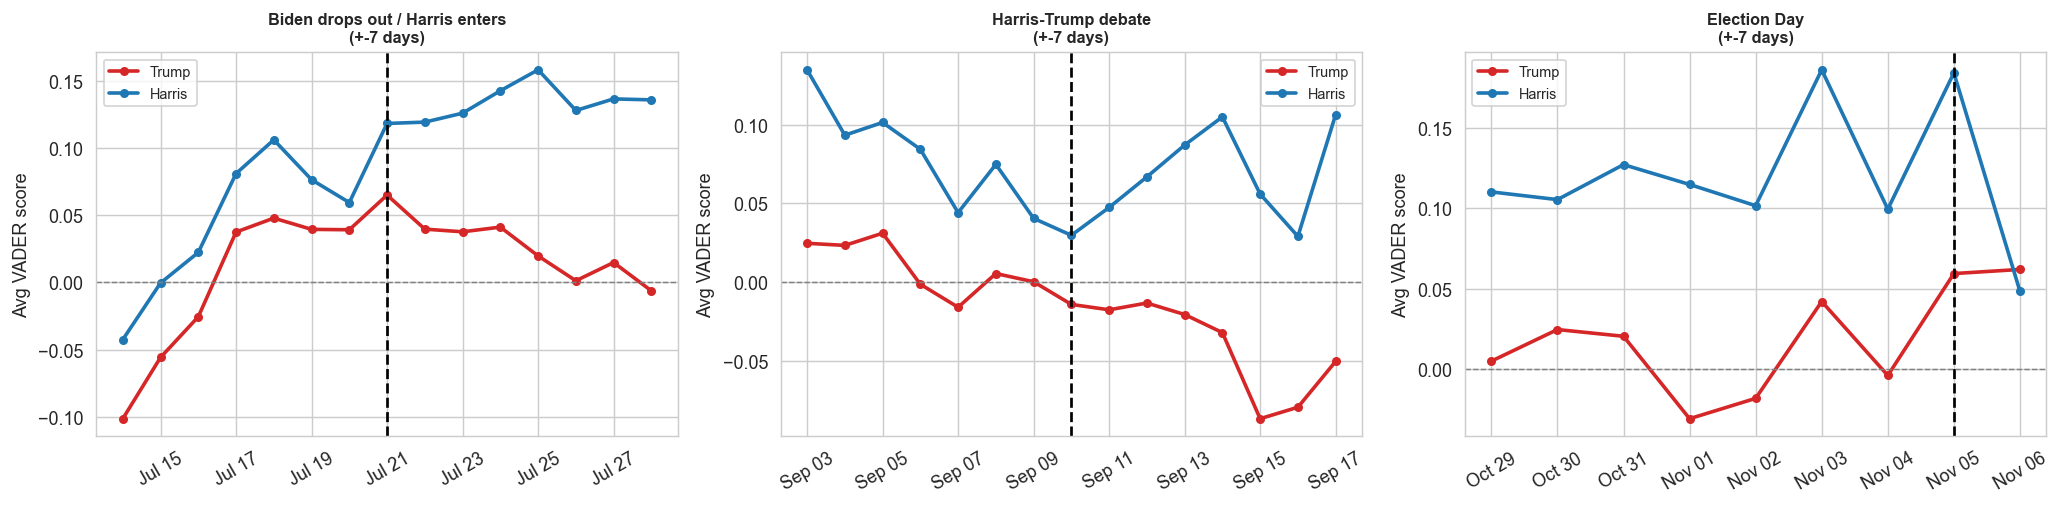

In [28]:
key_events_zoom = {
    '2024-07-21': 'Biden drops out / Harris enters',
    '2024-09-10': 'Harris-Trump debate',
    '2024-11-05': 'Election Day',
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (date_str, event_label) in zip(axes, key_events_zoom.items()):
    center = pd.to_datetime(date_str)
    window = df_comments[
        (df_comments['date_day'] >= center - pd.Timedelta('7D')) &
        (df_comments['date_day'] <= center + pd.Timedelta('7D'))
    ]
    trump_w  = window[window['mentions_trump']].groupby('date_day')['vader_score'].mean()
    harris_w = window[window['mentions_harris/biden']].groupby('date_day')['vader_score'].mean()
    ax.plot(trump_w.index,  trump_w.values,  color='#d62728', linewidth=2, marker='o', markersize=4, label='Trump')
    ax.plot(harris_w.index, harris_w.values, color='#1f77b4', linewidth=2, marker='o', markersize=4, label='Harris')
    ax.axvline(center, color='black', linestyle='--', linewidth=1.5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'{event_label}\n(+-7 days)', fontweight='bold', fontsize=9)
    ax.set_ylabel('Avg VADER score')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 10. Modeling Implications

Key takeaways from EDA that directly inform the three modeling approaches.

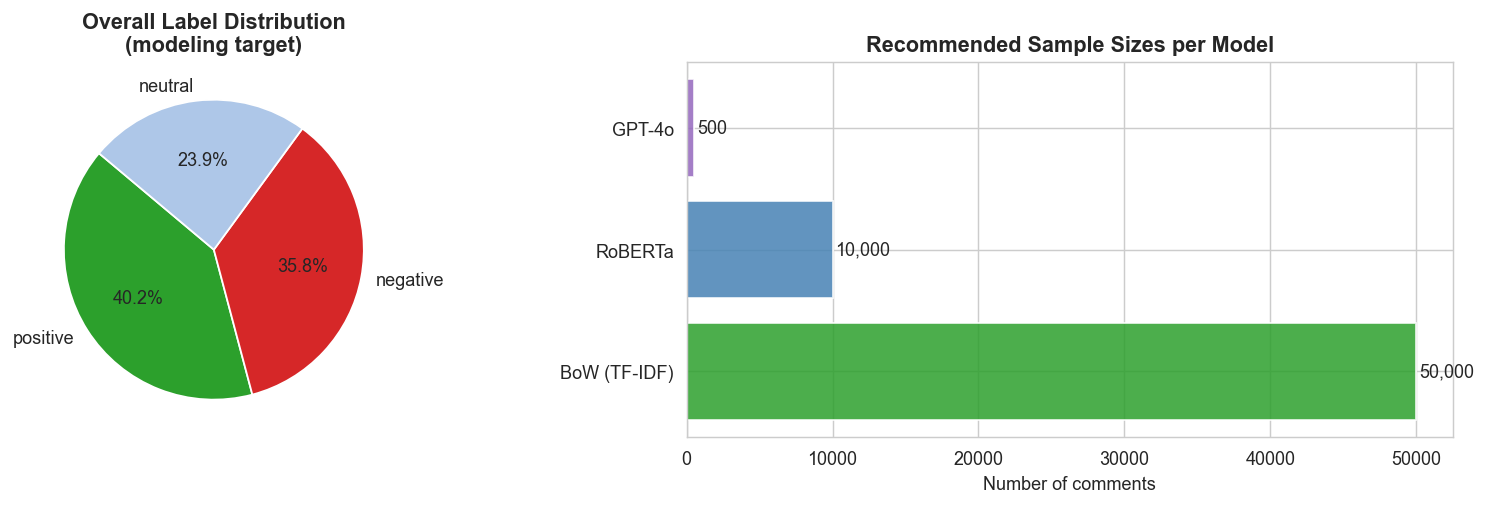

=== Key Modeling Notes ===
Total labeled comments: 6,553,662
  positive  : 2,637,290 (40.2%)
  negative  : 2,347,946 (35.8%)
  neutral   : 1,568,426 (23.9%)

Recommended split: 80/20, stratified by vader_label


In [32]:
label_counts = df_comments['vader_label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].pie(label_counts.values, labels=label_counts.index,
            colors=[colors_map[l] for l in label_counts.index],
            autopct='%1.1f%%', startangle=140)
axes[0].set_title('Overall Label Distribution\n(modeling target)', fontweight='bold')

total = len(df_comments)
bow_n, roberta_n, gpt_n = min(50_000, total), min(10_000, total), min(500, total)
axes[1].barh(['BoW (TF-IDF)', 'RoBERTa', 'GPT-4o'],
             [bow_n, roberta_n, gpt_n],
             color=['#2ca02c', 'steelblue', '#9467bd'], alpha=0.85)
axes[1].set_title('Recommended Sample Sizes per Model', fontweight='bold')
axes[1].set_xlabel('Number of comments')
for i, v in enumerate([bow_n, roberta_n, gpt_n]):
    axes[1].text(v + 200, i, f'{v:,}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

print('=== Key Modeling Notes ===')
print(f'Total labeled comments: {total:,}')
for l, c in label_counts.items():
    print(f'  {l:10s}: {c:,} ({c/total*100:.1f}%)')
print(f'\nRecommended split: 80/20, stratified by vader_label')


## 12. EDA Summary

| Category | Key Finding |
|---|---|
| Dataset size | **~6.56M comments** across 62k election-relevant threads (Jun–Nov 2024), after bot removal |
| Bot exclusion | 77,478 bot/AutoModerator comments removed (1.17% of raw total) via substring pattern matching |
| Data quality | No missing values; no duplicate comment IDs; 1 missing day (Aug 30) |
| Temporal | Clear volume spikes around key events (Biden exit, debates, Election Day) |
| Day/hour | Weekday peak; evening UTC = US afternoon activity |
| Comment structure | ~30–40% top-level; median ~10 comments/thread; some viral threads with 1000+ |
| Text length | Median ~100 chars; top-level comments longer than nested |
| N-grams | Bigrams/trigrams reveal campaign narratives beyond single keywords |
| Candidate framing | Trump mentioned more overall; Harris/Biden surge after Jul 21 |
| Score & engagement | Heavy right-skew; top-level scores higher than nested |
| VADER labels | ~40% neutral, ~35% positive, ~25% negative on comment bodies |
| VADER limitation | Misses slang/memes — GPT-4o handles these better |
| Sentiment over time | Reacts to events; Harris/Biden-mention comments trend more positive |
| Sentiment gap | Track Trump-minus-Harris gap to see narrative dominance shifts |
| Event zooms | Clear before/after sentiment shifts visible around key dates |
| Polling correlation | Weak Pearson r — Reddit sentiment does not directly track national polls |
| Modeling input | `df_comments_vader.parquet`, stratified 80/20 split on `vader_label` |